# ACCF

Interface to the ACCF (algorithmic climate change functions) from the DLR library [climaccf](https://github.com/dlr-pa/climaccf).

## References

- Dietmüller, Simone. “Dlr-Pa/Climaccf: Dataset Update for GMDD.” Zenodo, September 13, 2022. https://doi.org/10.5281/zenodo.7074582.
- Dietmüller, Simone, Sigrun Matthes, Katrin Dahlmann, Hiroshi Yamashita, Abolfazl Simorgh, Manuel Soler, Florian Linke, et al. “A Python Library for Computing Individual and Merged Non-CO<sub>2</sub> Algorithmic Climate Change Functions: CLIMaCCF V1.0.” Preprint. Atmospheric sciences, October 17, 2022. https://doi.org/10.5194/gmd-2022-203.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pycontrails import Flight
from pycontrails.datalib.ecmwf import ERA5
from pycontrails.models.accf import ACCF
from pycontrails.physics import units

## Set Domain

time / altitude

In [2]:
time_bounds = ("2022-01-01 12:00:00", "2022-01-01 15:00:00")
pressure_levels = [200, 225, 250]

## Download meteorology data from ECMWF

This demo uses [ERA5](https://climate.copernicus.eu/climate-reanalysis) via the [Copernicus Data Store (CDS)](https://cds.climate.copernicus.eu/) for met data.
This requires account with [Copernicus Data Portal](https://cds.climate.copernicus.eu/how-to-api) and local `~/.cdsapirc` file with credentials.

In [3]:
# pressure level data
era5_pl = ERA5(
    time=time_bounds,
    variables=ACCF.met_variables,
    pressure_levels=pressure_levels,
)

# single level data (radiation)
era5_sl = ERA5(
    time=time_bounds,
    variables=ACCF.sur_variables,
)

pl = era5_pl.open_metdataset()
sl = era5_sl.open_metdataset()

## Create example flight

In [4]:
# Note: ACCF output is in K/kg of fuel so you will need to provide fuel burn of the flight to get impact in K
n = 10000
longitude = np.linspace(45, 58, n) + np.linspace(0, 1, n)
latitude = np.linspace(45, 54, n) - np.linspace(0, 1, n)
altitude = units.pl_to_m(225) * np.ones(n)

start = np.datetime64(time_bounds[0])
end = start + np.timedelta64(90, "m")  # 90 minute flight
time = pd.date_range(start, end, periods=n, unit="ns")
fl = Flight(
    longitude=longitude,
    latitude=latitude,
    altitude=altitude,
    time=time,
    aircraft_type="B737",
    flight_id=17,
)
fl["fuel_flow"] = np.linspace(2.1, 2.4, n)  # kg/s

In [5]:
fl

Flight [5 keys x 10000 length, 2 attributes]
	Keys: longitude, latitude, time, altitude, fuel_flow
	Attributes:
	time                [2022-01-01 12:00:00, 2022-01-01 13:30:00]
	longitude           [45.0, 59.0]
	latitude            [45.0, 53.0]
	altitude            [11037.0, 11037.0]
	aircraft_type       B737
	flight_id           17

## Initialize ACCF model and evaluate on flight

In [6]:
ac = ACCF(met=pl, surface=sl, unit_K_per_kg_fuel=True)

In [7]:
# Evaluate ACCFs over this flight
fl = ac.eval(fl)

Forecast step has not been selected manually and determined automatically. Forecast step: 1 hour




## Explore the output

Raw output:

In [8]:
fl

Flight [27 keys x 10000 length, 6 attributes]
	Keys: longitude, latitude, time, altitude, fuel_flow, ..., Fin
	Attributes:
	time                [2022-01-01 12:00:00, 2022-01-01 13:30:00]
	longitude           [45.0, 59.0]
	latitude            [45.0, 53.0]
	altitude            [11037.0, 11037.0]
	aircraft_type       B737
	flight_id           17
	met_source_provider ECMWF
	met_source_dataset  ERA5
	met_source_product  reanalysis
	pycontrails_version 0.65.1.dev10

Now convert fuel flow to total fuel burned by waypoint, and get the impact of each flight waypoint and plot

In [9]:
# Waypoint duration in seconds
dt_sec = fl.segment_duration()

# kg fuel per contrail
fuel_burn = fl["fuel_flow"] * dt_sec

# Get impacts in degrees K per waypoint
warming_contrails = fuel_burn * fl["aCCF_Cont"]
warming_merged = fuel_burn * fl["aCCF_merged"]

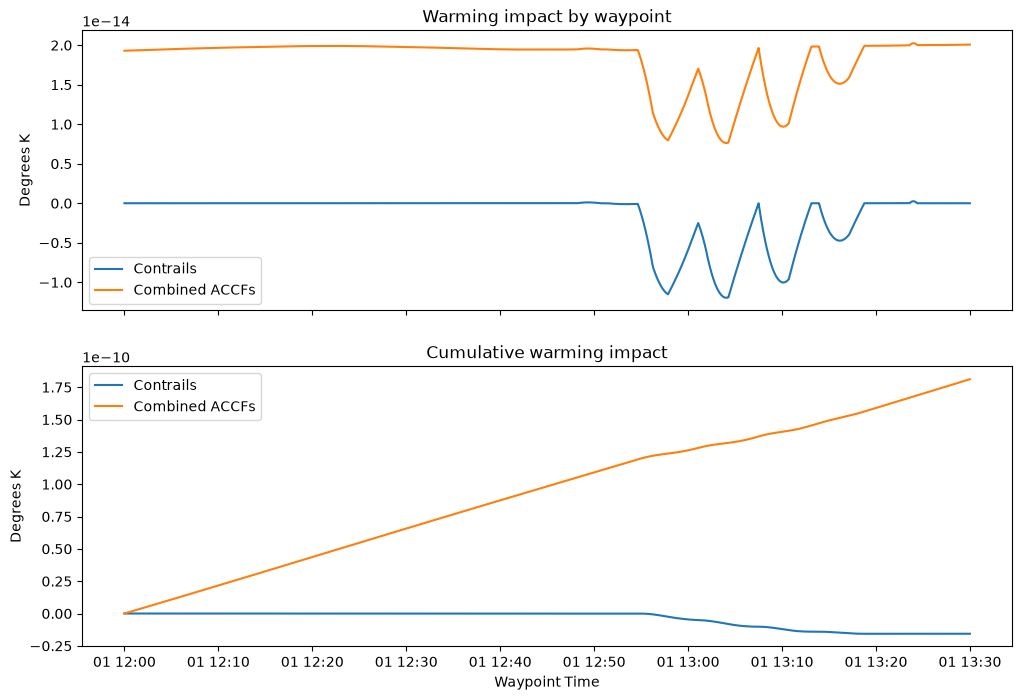

In [10]:
f, (ax0, ax1) = plt.subplots(2, 1, sharex=True, figsize=(12, 8))
ax0.plot(fl["time"], warming_contrails, label="Contrails")
ax0.plot(fl["time"], warming_merged, label="Combined ACCFs")
ax0.set_ylabel("Degrees K")
ax0.set_title("Warming impact by waypoint")
ax0.legend()

ax1.plot(fl["time"], np.cumsum(warming_contrails), label="Contrails")
ax1.plot(fl["time"], np.cumsum(warming_merged), label="Combined ACCFs")
ax1.legend()
ax1.set_xlabel("Waypoint Time")
ax1.set_ylabel("Degrees K")
ax1.set_title("Cumulative warming impact");

## Grid ACCF with Parameters

In [11]:
ac = ACCF(
    met=pl,
    surface=sl,
    emission_scenario="future_scenario",
    accf_v="V1.0",
    unit_K_per_kg_fuel=True,
)
ds = ac.eval()  # This will evaluate over the met grid

Forecast step has not been selected manually and determined automatically. Forecast step: 1 hour




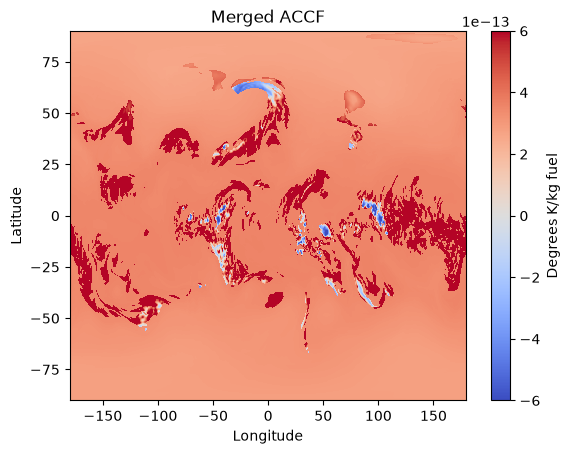

In [12]:
fig, ax = plt.subplots()
p = ax.pcolor(
    ds["longitude"].data,
    ds["latitude"].data,
    ds["aCCF_merged"].data[:, :, 0, 0].T,
    cmap="coolwarm",
    vmin=-6e-13,
    vmax=6e-13,
)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Merged ACCF")
cbar = plt.colorbar(p)
cbar.set_label("Degrees K/kg fuel");